# Przetwarzanie danych: korpusy In Domain i Out of Domain

Notebook buduje `data/meajor_processed.parquet` (In Domain: Nazario, Nigerian, TREC 05-07) oraz
`data/external_processed.parquet` (Out of Domain: FERB, KD, NEBULON, Zero-Day), a także wszystkie tabele
(CSV) i wykresy (wektorowe PDF) opisujące te dane.

Etapy: **1** zbieranie, **2** czyszczenie i maskowanie, **3** deduplikacja, **4** klastrowanie prawie-duplikatów,
**5** zapis korpusu ID, **6** korpus OOD i nakładanie na ID, **7** tabele, **8** wykresy.

In [ ]:
import csv
import email
import html
import multiprocessing as mp
import os
import re
import unicodedata
import zlib
from email.header import decode_header, make_header
from html.parser import HTMLParser
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results" / "data_processing"
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
N_WORKERS = max(1, (os.cpu_count() or 2) - 2)
csv.field_size_limit(2**31 - 1)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100)


def parallel_map(function, items, chunksize=200):
    with mp.get_context("fork").Pool(N_WORKERS) as pool:
        return pool.map(function, items, chunksize=chunksize)


def save_table(frame, name, index=True):
    frame.to_csv(TABLES / f"{name}.csv", index=index)
    display(frame)

## 1. Zbieranie surowych wiadomości

Nazario to pliki mbox, pozostałe źródła to CSV. Czytamy je modułem `csv`, bo w TREC 05 i 06 parser C pandas
przerywa pracę na uszkodzonych wierszach. Wiersze z błędną liczbą kolumn (rozbite przez znak CR w niepoprawnie
zakodowanych wiadomościach) są odrzucane i liczone w tabeli lejka.

In [ ]:
ID_SOURCES = {
    "nigerian": dict(path=DATA / "Nigerian_Fraud.csv", kinds={"1": "phishing"}),
    "trec05": dict(path=DATA / "TREC_05.csv", kinds={"1": "spam", "0": "ham"}),
    "trec06": dict(path=DATA / "TREC_06.csv", kinds={"1": "spam", "0": "ham"}),
    "trec07": dict(path=DATA / "TREC_07.csv", kinds={"1": "spam", "0": "ham"}),
}
NAZARIO_FILES = [
    "20051114.mbox", "phishing-2015.txt", "phishing-2016.txt", "phishing-2017.txt", "phishing-2018.txt",
    "phishing-2019.txt", "phishing-2020.txt", "phishing-2021.txt", "phishing-2022.txt", "phishing-2023.txt",
    "phishing-2024.txt", "phishing-2025.txt", "phishing0.mbox", "phishing1.mbox", "phishing2.mbox",
    "phishing3.mbox", "private-phishing4.mbox",
]
MBOX_SEPARATOR = re.compile(
    rb"(?m)^From \S+\s+(?:Mon|Tue|Wed|Thu|Fri|Sat|Sun)\s+"
    rb"[A-Z][a-z]{2}\s+\d{1,2}\s+\d{2}:\d{2}(?::\d{2})?\s+"
    rb"(?:[+-]?\d{4} )?\d{4}"
)
FUNNEL = {}


def decode_mail_header(value):
    if value is None:
        return ""
    try:
        return str(make_header(decode_header(str(value))))
    except Exception:
        return str(value)


def decode_payload(part):
    raw = part.get_payload(decode=True) or b""
    for encoding in (part.get_content_charset(), "utf-8", "cp1252"):
        if not encoding:
            continue
        try:
            return raw.decode(encoding)
        except (LookupError, UnicodeDecodeError):
            continue
    return raw.decode("latin1")


def mbox_body(message):
    plain, rich = [], []
    for part in message.walk():
        if part.is_multipart() or part.get_content_disposition() == "attachment":
            continue
        if part.get_content_type() == "text/plain":
            plain.append(decode_payload(part))
        elif part.get_content_type() == "text/html":
            rich.append(decode_payload(part))
    return "\n".join(plain) if "".join(plain).strip() else "\n".join(rich)


def read_nazario():
    rows = []
    for name in NAZARIO_FILES:
        data = (DATA / "nazario" / name).read_bytes()
        starts = [match.start() for match in MBOX_SEPARATOR.finditer(data)] + [len(data)]
        year = re.search(r"(20\d{2})", name)
        for position, (start, end) in enumerate(zip(starts[:-1], starts[1:])):
            chunk = data[start:end]
            message = email.message_from_bytes(chunk[chunk.find(b"\n") + 1:])
            rows.append((
                f"{name}:{position}", name, float(year.group(1)) if year else np.nan, decode_mail_header(message["from"]),
                str(message["date"] or ""), decode_mail_header(message["subject"]), mbox_body(message),
            ))
    frame = pd.DataFrame(rows, columns=["raw_key", "file", "year_file", "sender", "date", "subject", "body"])
    frame["kind"] = "phishing"
    return frame


def read_csv_rows(path):
    with open(path, newline="", encoding="utf-8-sig", errors="replace") as handle:
        reader = csv.reader(handle)
        header = next(reader)
        rows, malformed = [], 0
        for row in reader:
            if len(row) == len(header):
                rows.append(row)
            else:
                malformed += 1
    return pd.DataFrame(rows, columns=header, dtype="str"), malformed


def drop_pseudo_messages(frame):
    pseudo = (
        frame.sender.str.contains("MAILER-DAEMON", case=False)
        & frame.subject.str.contains("DON'T DELETE THIS MESSAGE", case=False)
    )
    return frame[~pseudo].copy(), int(pseudo.sum())


raw_parts = []
nazario = read_nazario()
kept, pseudo_count = drop_pseudo_messages(nazario)
kept["source"] = "nazario"
raw_parts.append(kept)
FUNNEL["nazario"] = {"surowe": len(nazario), "błędna_struktura": 0, "uszkodzone": 0, "pseudo_wiadomości": pseudo_count}

for name, config in ID_SOURCES.items():
    frame, malformed = read_csv_rows(config["path"])
    labels = frame["label"].str.strip()
    valid = labels.isin(config["kinds"]) & (frame.receiver.str.len() < 100_000)
    kept = frame[valid].fillna("").copy()
    kept["kind"] = labels[valid].map(config["kinds"])
    kept["file"], kept["year_file"] = config["path"].name, np.nan
    kept["raw_key"] = config["path"].name + ":" + kept.index.astype(str)
    kept, pseudo_count = drop_pseudo_messages(kept)
    kept["source"] = name
    raw_parts.append(kept)
    FUNNEL[name] = {
        "surowe": len(frame) + malformed, "błędna_struktura": malformed,
        "uszkodzone": int((~valid).sum()), "pseudo_wiadomości": pseudo_count,
    }
raw_id = pd.concat(raw_parts, ignore_index=True)
del raw_parts, nazario
print(pd.DataFrame(FUNNEL).T)

          surowe  błędna_struktura  uszkodzone  pseudo_wiadomości
nazario    12006                 0           0                  9
nigerian    3332                 0           0                  0
trec05     56088               813           6                  0
trec06     16463                63           0                  0
trec07     53757                 0           0                  0


## 2. Czyszczenie i maskowanie tekstu

Usuwamy artefakty (HTML, CSS, MIME, base64, mojibake, nagłówki filtrów), powtórzenia w tekście oraz maskujemy
adresy URL, e-maile, domeny, ścieżki, lata i numery telefonów. Maskowanie usuwa też nazwy własne ujawniające
źródło danych (`enron`, `jose`, `nazario`, `monkey`). Tekst jest przycinany do `MAX_STORE` znaków treści.

In [ ]:
MAX_INPUT, MAX_STORE, MAX_SUBJECT, MIN_CHARS = 200_000, 10_000, 500, 20
HTML_TAGS = "a|font|img|br|div|table|tbody|tr|td|p|body|html|head|style|h[1-6]"
CSS_SELECTOR = (
    r"(?:(?:p|a|li|ul|ol|td|th|tr|body|html|table|tbody|img|h[1-6]|div|span|font|b|i|u|strong|em|hr|center"
    r"|blockquote|pre|input|form|\*)(?:[.#:][\w-]+)*|[.#][A-Za-z_][\w-]*(?:[.#:][\w-]+)*)"
)
CSS_PROPERTY = (
    r"(?:margin(?:-[\w-]+)?|padding(?:-[\w-]+)?|font(?:-[\w-]+)?|line-height|text-(?:align|indent|transform|decoration)"
    r"|color|background(?:-color)?|border(?:-[\w-]+)?|vertical-align|display|orphans|widows|cursor)"
)
CSS_DECLARATION = rf"(?<![\w-]){CSS_PROPERTY}\s*:\s*[^;<>\n]{{0,120}}"

_BLOCK = re.compile(r"<(script|style)\b.*?</\1>", re.I | re.S)
_CSS_AT_RULE = re.compile(r"(?i)@(?:media|font-face|page)[^{};]{0,200}\{(?:[^{}]*\{[^{}]*\})*[^{}]*\}|@(?:import|charset)[^;\n]{0,200};")
_CSS_RULE = re.compile(
    rf"(?<![\w-]){CSS_SELECTOR}(?:(?:\s*[,>+~]\s*|\s+){CSS_SELECTOR})*\s*\{{([^{{}}]{{0,4000}})\}}", re.I
)
_CSS_COMMENT = re.compile(r"/\*.*?\*/", re.S)
_HTML_COMMENT_MARKER = re.compile(r"<!--|-->")
_ORPHAN_HTML_DELIMITER = re.compile(r"(?m)^[ \t]*[<>][ \t]*$|[ \t]+[<>][ \t]*$")
_MIME_NOISE = re.compile(r"(?im)^[ \t]*(?:content-(?:transfer-encoding|id|type|disposition):.*|boundary\s*=.*)$")
_FILTER_HEADERS = re.compile(r"(?im)^[ \t]*(?:X-Spam-[A-Za-z0-9-]+|DKIM-Signature):[^\n]*(?:\n[ \t]+[^\n]*)*")
_INLINE_FILTER_HEADERS = re.compile(
    r"(?i)\b(?:X-Spam-(?:Flag|Score|Level|Status)|DKIM-Signature):\s*"
    r"(?:[^<\n]|<(?!/?(?:html|head|body|div|table|p|a|font)\b)){0,500}?"
    r"(?=(?:\s+\b(?:Received|Return-Path|From|To|Subject|Date|MIME-Version|Content-)|<|$))"
)
_INLINE_MIME_HEADERS = re.compile(r"(?i)\bContent-(?:Type|ID|Disposition|Transfer-Encoding):\s*[^\s<]{1,160}(?:\s*;\s*[^<\s]{1,160})?")
_BROKEN_HTML_TAG = re.compile(
    rf"(?i)</?(?:{HTML_TAGS})\b(?:\s+[\w-]+\s*=\s*(?:\"[^\"\n]*\"?|'[^'\n]*'?|[^\s<>]*))*\s*(?=<|\n|$)"
)
_HTML_TAG_START = re.compile(rf"(?i)</?(?:{HTML_TAGS})\b")
_TAG = re.compile(r"</?[A-Za-z][^<>]*>", re.S)
_BASE64_LINE = re.compile(r"(?im)^[ \t]*[A-Za-z0-9+/]{80,}={0,2}[ \t]*$")
_BASE64_RUN = re.compile(r"(?<![A-Za-z0-9+/=])[A-Za-z0-9+/]{40,}={0,2}(?![A-Za-z0-9+/=])")
_BASE64_RUN_LOOSE = re.compile(r"[A-Za-z0-9+/]{40,}={0,2}")
_BASE64_SPACED = re.compile(r"(?<![A-Za-z0-9+/=])(?:[A-Za-z0-9+/]{2,}\s+){20,}?[A-Za-z0-9+/]{2,}={1,2}(?![A-Za-z0-9+/=])")
_DATA_IMAGE = re.compile(r"(?is)<img\b[^>]*data:image/[^>]*>?|data:image/[^;<>]{1,40};\s*base64\s*,\s*[A-Za-z0-9+/=\s]*")
_HIDDEN_HTML_FRAGMENT = re.compile(
    r"(?is)style\s*=\s*[\"'][^\"'\n]{0,500}?(?:font-size\s*:\s*0(?:px|pt|em|rem)?|display\s*:\s*none)"
    r"[^\"'\n]*[\"']\s*>\s*[^<\n]{0,160}(?=\s+(?:style|class|width|height|color|align)\s*=)"
)
_STYLE_RESIDUE = re.compile(
    r"(?is)(?:(?:rgb\([^)]*\)|(?:text-transform|letter-spacing|font-family|font-size|font-style|font-weight|word-spacing"
    r"|white-space|border-collapse|max-width|orphans|widows|background-color|font-variant(?:-ligatures|-caps)?"
    r"|-webkit-text-stroke-width|text-decoration-(?:thickness|style|color))\s*:\s*[^;<>]{0,240});\s*){2,}[\"'>]?"
)
_ORPHAN_HTML_ATTRIBUTE = re.compile(
    r"(?i)(?<![\w-])(?:(?:style|class|width|height|color|align|border|face|vlink|alink|bgcolor|leftmargin|topmargin"
    r"|marginwidth|marginheight|background|cellpadding|cellspacing|valign|alt|src|href|size|rowspan|colspan"
    r"|bordercolor(?:light|dark)?|summary|jslog)\s*=\s*(?:\"[^\"]{0,500}\"|'[^']{0,500}'|\#?[0-9a-f]{1,8}%?(?![\w-]))"
    r"|(?:src|href)\s*=\s*[^\s<>]{1,160}"
    r"|(?:style|class|width|height|color|align|border|face|bgcolor|background|valign|size)\s*=\s*[^\s<>\"']{1,80}(?=>))\s*>?"
)
_ORPHAN_CSS = re.compile(rf"(?i)(?:{CSS_DECLARATION};\s*){{2,}}[\"'>]*|{CSS_DECLARATION};?\s*[\"']\s*>")
_EMAIL_HTML_ATTRIBUTE_LINE = re.compile(
    r"(?im)^[ \t]*(?=[^\n]{80,}(?:gmail-(?:m_|yiv)|yiv\d+|yui_\d+)[^\n]*(?:gmail-(?:m_|yiv)|yiv\d+|yui_\d+))[^\n]*$"
)
_CUT = re.compile(r"^[ \t]*(?:on .{5,120} wrote:|.{0,120}\bwrote:|(?:-{2,}[ \t]*)?original message(?:[ \t]*-{2,})?)[ \t]*$", re.I | re.M)
_REPLY_PREFIX = re.compile(r"^(?:\s*(?:(?:re|fw|fwd|aw|tr)(?:\[\d+\])?\s*:|\[[^\]\n]{1,40}\]))+\s*", re.I)
_URL = re.compile(r"(?:https?://|ftp://|www\.)[^\s<>\"')\]]+", re.I)
_DEFANGED_URL = re.compile(r"\b(?:hxxps?|htps?|htp|ttps?)://[^\s<>\"')\]]+", re.I)
_MAIL = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
_PATH = re.compile(r"(?<![\w/])(?:[A-Za-z]:\\|/)(?:[\w.-]+[/\\])+[\w.-]+")
_PHONE = re.compile(r"(?<![\w$])\+?\(?\d[\d ().-]{5,}\d(?![\w%])")
_INVISIBLE = re.compile("[\u200b-\u200f\u2060\ufeff\ufffd]")
_CONTROL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")
_HREF = re.compile(r"""<a\b[^>]*?\bhref\s*=\s*["']?([^"'\s>]+)[^>]*>""", re.I | re.S)
_WEB_LINK = re.compile(r"(?i)^(?:https?://|ftp://|www\.|hxxps?://)")
_DOMAIN = re.compile(
    r"\b(?:[a-z0-9-]+\.)+(?:com|org|net|edu|gov|info|biz|uk|de|ru|cn|io|ca|au|fr|es|nl|jp|kr|br|xyz|top)\b", re.I
)
_YEAR = re.compile(r"(?<![\d-])(?:19|20)\d{2}(?![\d-])(?!\s*(?:dollars?|usd|eur|gbp|pounds?|euros?))", re.I)
_NAMES = re.compile(r"\b(?:enron|jose|nazario|monkey)\b", re.I)
_Q = r"(?:\s*+>++)*+\s*+"
_LIST_FOOTER = re.compile("(?:" + "|".join([
    r"(?:_{3,}\s*)?(?:\[EMAIL_ADDRESS\]|(?<![\w.+-])[\w.+-]{1,60}+)\s++mailing list" + _Q + r"(?:\[EMAIL_ADDRESS\]" + _Q + r")?\[(?:URL|EMAIL_ADDRESS)\]",
    r"PLEASE do read the posting guide" + _Q + r"(?:\[URL\])?" + _Q + r"and provide commented, minimal, self-contained, reproducible code\.?",
    r"To unsubscribe, e-mail:" + _Q + r"\[EMAIL_ADDRESS\]" + _Q + r"For additional commands, e-mail:" + _Q + r"\[EMAIL_ADDRESS\](?:" + _Q + r"\[URL\])?",
    r"To UNSUBSCRIBE, email to" + _Q + r"\[EMAIL_ADDRESS\]" + _Q + r'with a subject of "unsubscribe"\.' + _Q + r"Trouble\?" + _Q + r"Contact" + _Q + r"\[EMAIL_ADDRESS\]",
    r"(?:Yahoo! Groups (?:Sponsor|Links)\s*(?:ADVERTISEMENT\s*)?)?To unsubscribe from this group, send an email to:" + _Q + r"\[EMAIL_ADDRESS\]"
    + r"(?:" + _Q + r"Your use of Yahoo! Groups is subject to(?:" + _Q + r"the Yahoo!" + _Q + r"Terms of Service\.?|" + _Q + r"\[URL\]))?",
    r"\[\[alternative HTML version deleted\]\]",
]) + ")" + _Q, re.I)
_QUOTE_MARKERS = re.compile(r"(?<!\S)(?:>{2,}|>(?:[ \t]+>)+)(?!\S)")
_ALPHA = re.compile(r"[a-z']+")
_REPEATED_WORD = re.compile(r"\b(\w+)(?:\s+\1\b){2,}", re.I)
_REPEATED_TOKEN = re.compile(r"(\[[A-Z_]+\])(?:\s*\1)+")
_DECORATION = re.compile(r"(?m)^[ \t]*(?:[*=_#~-][ \t]*){3,}$|[*=_#~-]{4,}|[\u2500-\u257f]{2,}")
_BROKEN_SEPARATOR = re.compile(r"\s*TD2EW1LZ\s*", re.I)
_MOJIBAKE = re.compile(r"[ÃÂâð]", re.I)
_STRAY_A_CIRCUMFLEX = re.compile(r"Â(?=\s|\w|[©®¿])|(?<=\s)Â(?=\w)")
EN_STOP = set(
    "the and to of a in is you your for this that it with on are be as at from or by an have will not we can our "
    "please if all has was but they their which more any".split()
)
MAX_REPEAT_SENTENCES = 16
REPEAT_BLOCK_SIZES = tuple(range(8, 25)) + tuple(range(32, 65, 8))
HASH_MASK, HASH_BASE = (1 << 64) - 1, 1_000_003


class TextExtractor(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []

    def handle_data(self, data):
        self.parts.append(data)

    def handle_starttag(self, tag, attrs):
        if tag in {"br", "p", "div", "tr", "li", "hr"}:
            self.parts.append("\n")

    def handle_endtag(self, tag):
        if tag in {"p", "div", "tr", "li"}:
            self.parts.append("\n")


def strip_html(text):
    if not (_TAG.search(text) or _HTML_TAG_START.search(text)):
        return text
    parser = TextExtractor()
    parser.feed(_BROKEN_HTML_TAG.sub(" ", text))
    parser.close()
    result = _TAG.sub(" ", "".join(parser.parts))
    return _ORPHAN_HTML_DELIMITER.sub(" ", _HTML_TAG_START.sub(" ", result))


def strip_css(text):
    if "{" not in text:
        return text
    text = _CSS_AT_RULE.sub(" ", _CSS_COMMENT.sub(" ", text))
    return _CSS_RULE.sub(lambda match: " " if ":" in match.group(1) or not match.group(1).strip() else match.group(0), text)


def keep_web_link(match):
    return f" {match.group(1)} " if _WEB_LINK.match(match.group(1)) else " "


def remove_spaced_base64(text):
    def replace(match):
        return " " if len(re.sub(r"\s+", "", match.group(0))) >= 160 else match.group(0)
    return _BASE64_SPACED.sub(replace, text)


def repair_mojibake(text):
    if not _MOJIBAKE.search(text):
        return text
    try:
        raw = bytearray()
        for char in text:
            try:
                raw.extend(char.encode("cp1252"))
            except UnicodeEncodeError:
                if ord(char) > 255:
                    return text
                raw.append(ord(char))
        repaired = bytes(raw).decode("utf-8")
    except UnicodeDecodeError:
        return text
    return repaired if len(_MOJIBAKE.findall(repaired)) < len(_MOJIBAKE.findall(text)) else text


def dedupe_repeated_sentences(text):
    words = text.split()
    midpoint = len(words) // 2
    if len(words) % 2 == 0 and words[:midpoint] == words[midpoint:]:
        return " ".join(words[:midpoint])
    sentences = re.split(r"(?<=[.!?])\s+", text)
    if len(sentences) < 2:
        return text
    max_block = min(len(sentences) // 2, MAX_REPEAT_SENTENCES)
    for start in range(len(sentences) - 1):
        for size in range(max_block, 0, -1):
            middle = start + size
            if middle + size <= len(sentences) and sentences[start:middle] == sentences[middle:middle + size]:
                del sentences[middle:middle + size]
                return " ".join(sentences)
    return text


def dedupe_repeated_blocks(text):
    words = text.split()
    if len(words) < 16:
        return text
    sizes = [size for size in REPEAT_BLOCK_SIZES if size <= len(words) // 2]
    ids = {}
    prefix, powers = [0], [1]
    for word in words:
        prefix.append((prefix[-1] * HASH_BASE + ids.setdefault(word, len(ids) + 1)) & HASH_MASK)
    for _ in range(max(sizes)):
        powers.append((powers[-1] * HASH_BASE) & HASH_MASK)

    def window(start, size):
        return (prefix[start + size] - prefix[start] * powers[size]) & HASH_MASK

    for start in range(len(words) - 2 * REPEAT_BLOCK_SIZES[0] + 1):
        for size in reversed(sizes):
            if start + 2 * size > len(words) or window(start, size) != window(start + size, size):
                continue
            block = words[start:start + size]
            if block != words[start + size:start + 2 * size]:
                continue
            end = start + 2 * size
            while end + size <= len(words) and words[end:end + size] == block:
                end += size
            words[start:end] = block
            return " ".join(words)
    return text


def mask_phone(match):
    value = match.group(0)
    if sum(char.isdigit() for char in value) < 7 or not re.search(r"[ ().-]", value):
        return value
    groups = re.split(r"[ .-]+", value.strip("+() "))
    if "." in value and not re.search(r"[ ()-]", value) and max(map(len, groups)) <= 3:
        return value
    if len(groups) >= 5 and max(map(len, groups)) <= 2:
        return value
    return "[PHONE_NUMBER]"


def mask(text):
    text = _DEFANGED_URL.sub(" [URL] ", _URL.sub(" [URL] ", text))
    text = _MAIL.sub(" [EMAIL_ADDRESS] ", text)
    text = _DOMAIN.sub(" [DOMAIN] ", text)
    text = _PATH.sub(" [FILE_PATH] ", text)
    text = _YEAR.sub("[YEAR]", text)
    return _NAMES.sub(" ", _PHONE.sub(mask_phone, text))


def tidy(text):
    text = _DECORATION.sub(" ", _BROKEN_SEPARATOR.sub(" ", text))
    text = _REPEATED_WORD.sub(r"\1", _REPEATED_TOKEN.sub(r"\1", text))
    text = re.sub(r"\s+", " ", text).strip()
    for _ in range(MAX_REPEAT_SENTENCES):
        shorter = dedupe_repeated_sentences(text)
        if shorter == text:
            break
        text = shorter
    for _ in range(2):
        shorter = dedupe_repeated_blocks(text)
        if shorter == text:
            break
        text = shorter
    return text


def clean_body(text):
    text = html.unescape(repair_mojibake(str(text)[:MAX_INPUT]))
    for pattern in (_FILTER_HEADERS, _INLINE_FILTER_HEADERS, _INLINE_MIME_HEADERS, _MIME_NOISE, _DATA_IMAGE,
                    _BASE64_LINE, _BASE64_RUN, _HIDDEN_HTML_FRAGMENT):
        text = pattern.sub(" ", text)
    text = remove_spaced_base64(text)
    text = strip_html(strip_css(_BLOCK.sub(" ", _HREF.sub(keep_web_link, text))))
    for pattern in (_HTML_COMMENT_MARKER, _STYLE_RESIDUE, _ORPHAN_HTML_ATTRIBUTE, _ORPHAN_CSS, _EMAIL_HTML_ATTRIBUTE_LINE):
        text = pattern.sub(" ", text)
    text = _INVISIBLE.sub("", unicodedata.normalize("NFKC", text))
    text = _STRAY_A_CIRCUMFLEX.sub("", _CONTROL.sub(" ", text))
    text = "\n".join(line for line in text.splitlines() if not line.lstrip().startswith(">"))
    match = _CUT.search(text)
    if match and len(text[:match.start()].strip()) >= MIN_CHARS:
        text = text[:match.start()]
    text = _CUT.sub(" ", text)
    text = _LIST_FOOTER.sub(" ", _QUOTE_MARKERS.sub(" ", mask(text)))
    return tidy(_BASE64_RUN_LOOSE.sub(" ", text))[:MAX_STORE]

def clean_subject(text):
    text = _REPLY_PREFIX.sub("", html.unescape(repair_mojibake(str(text))))
    return tidy(mask(_INVISIBLE.sub("", unicodedata.normalize("NFKC", text))))[:MAX_SUBJECT]

def en_ratio(text):
    words = _ALPHA.findall(re.sub(r"\[[A-Z_]+\]", " ", text).lower())
    return sum(word in EN_STOP for word in words) / len(words) if words else 0.0

def add_text_features(frame):
    frame = frame.copy()
    texts = frame.text.tolist()
    frame["n_chars"] = frame.text.str.len()
    frame["en_ratio"] = parallel_map(en_ratio, texts, chunksize=1000)
    frame["ascii_ratio"] = [len(text.encode("ascii", "ignore")) / max(len(text), 1) for text in texts]
    return frame

Testy regresyjne czyszczenia: treść wewnątrz znaczników, tekst obok nawiasów klamrowych i zwykłe zdania mają zostać,
a znaczniki, reguły CSS i dane wrażliwe na źródło mają zniknąć.

In [4]:
CLEANING_CASES = [
    ('<a href="http://evil.com/x">Click here</a> to verify your account', "[URL] Click here to verify your account"),
    ('<a href="mailto:x@y.com">Write</a> to us', "Write to us"),
    ('<p style="color:red">Hello dear customer</p><p>Second paragraph</p>', "Hello dear customer Second paragraph"),
    ('<font color="red" size=2>Important notice</font> please read', "Important notice please read"),
    ('<table width="100%" border=0><tr><td align="center">Your account is locked</td></tr></table>', "Your account is locked"),
    ('<img src="http://x.y/a.png" width=1 height=1>Visible text', "Visible text"),
    ("please use {name} in the first field and {other} in second {x}", "please use {name} in the first field and {other} in second {x}"),
    ("body { color:red } Text which must remain here. p { margin:0 } And more text.", "Text which must remain here. And more text."),
    ("<style>p {margin:0}</style>Styled mail body", "Styled mail body"),
    ("The color: red; shirt and size=large are in stock", "The color: red; shirt and size=large are in stock"),
    ("if a < b and c > d then we pay you 100 dollars", "if a < b and c > d then we pay you 100 dollars"),
    ("call 555-123-4567 in 2019 at www.foo.com / foo.bar.com / a@b.com", "call [PHONE_NUMBER] in [YEAR] at [URL] / [DOMAIN] / [EMAIL_ADDRESS]"),
    ("Dear jose, enron nazario monkey hello hello hello there", "Dear , hello there"),
    ("Thanks for the update on the budget.\n-----Original Message-----\nFrom: Kim\nquoted text", "Thanks for the update on the budget."),
    ("Thanks for the update on the budget.\nJohn Smith wrote:\nquoted text", "Thanks for the update on the budget."),
    ("On Wed, 10 Mar 2004, Tom wrote:\nThe reply below the quote stays", "The reply below the quote stays"),
    ("-----Original Message-----\nFrom: Kim\nForwarded offer text", "From: Kim Forwarded offer text"),
    ("Header ════════ Body \ufffdtext", "Header Body text"),
    ("limited for this reason. class=h6>To receive notifications", "limited for this reason. To receive notifications"),
    ("Offer =" + "FFFFA2" * 10 + "= today only", "Offer = today only"),
    ("Fix the scope. Paul -- To unsubscribe, e-mail: a@b.org For additional commands, e-mail: c@b.org http://learn.perl.org/",
     "Fix the scope. Paul --"),
    ("Use system(). _______________________________________________ R-help@stat.math.ethz.ch mailing list > https://stat.ethz.ch/mailman/listinfo/r-help"
     " > PLEASE do read the posting guide http://www.R-project.org/posting-guide.html > and provide commented, minimal, self-contained, reproducible code.",
     "Use system()."),
    ("It fixed the problem. Speakup mailing list Speakup@braille.uwo.ca http://speech.braille.uwo.ca/mailman/listinfo/speakup",
     "It fixed the problem."),
    ("Cheers, Terry -- To UNSUBSCRIBE, email to debian-legal-REQUEST@lists.debian.org with a subject of \"unsubscribe\". Trouble? Contact listmaster@lists.debian.org",
     "Cheers, Terry --"),
    ("Thanks >> Lauri >> >> [[alternative HTML version deleted]] > > done", "Thanks Lauri done"),
    ("Why is the R mailing list so hard to figure out? if a < b and c > d", "Why is the R mailing list so hard to figure out? if a < b and c > d"),
]
failures = [(given, expected, clean_body(given)) for given, expected in CLEANING_CASES if clean_body(given) != expected]
assert not failures, failures
SUBJECT_CASES = [
    ("Re: Fw: Meeting notes", "Meeting notes"), ("RE[2]: FWD: offer", "offer"), ("Regarding your account", "Regarding your account"),
    ("[R] problem with hist()", "problem with hist()"), ("Re: [DMDX] Re: No Keyboard Input", "No Keyboard Input"),
]
failures += [(given, expected, clean_subject(given)) for given, expected in SUBJECT_CASES if clean_subject(given) != expected]
assert not failures, failures
print(f"Testy czyszczenia: {len(CLEANING_CASES) + len(SUBJECT_CASES)} OK")

Testy czyszczenia: 31 OK


In [ ]:
def raw_document(frame):
    return (frame.subject.fillna("") + "\n" + frame.body.fillna("")).str.strip()


def plausible_year(dates):
    years = pd.to_datetime(dates, errors="coerce", utc=True, format="mixed").dt.year
    return years.where(years.between(1990, 2026))

clean_id = pd.DataFrame({
    "raw_key": raw_id.raw_key,
    "source": raw_id.source,
    "kind": raw_id.kind,
    "file": raw_id.file,
    "year_file": raw_id.year_file,
    "subject": parallel_map(clean_subject, raw_id.subject.fillna("").tolist()),
    "body": parallel_map(clean_body, raw_id.body.fillna("").tolist()),
    "sender_domain": raw_id.sender.fillna("").str.extract(r"@([\w.-]+)", expand=False).str.lower(),
    "year": plausible_year(raw_id.date),
    "raw_text": raw_document(raw_id),
})
clean_id["text"] = (clean_id.subject + "\n" + clean_id.body).str.strip()
del raw_id
print(f"Wyczyszczono {len(clean_id)} wiadomości ID")

Wyczyszczono 140755 wiadomości ID


## 3. Deduplikacja

Odrzucamy teksty krótsze niż `MIN_CHARS`, wszystkie kopie tekstów o sprzecznych klasach i duplikaty dokładne.
Sprzeczność liczymy po `kind`, więc ten sam tekst w Nazario i Nigerian jest zwykłym duplikatem, a nie konfliktem.

In [ ]:
def deduplicate(frame):
    short = frame.text.str.len() < MIN_CHARS
    long_enough = frame[~short]
    conflict = long_enough.groupby("text")["kind"].transform("nunique") > 1
    candidates = long_enough[~conflict]
    duplicate = candidates.duplicated("text")
    stats = pd.DataFrame({
        "za_krótkie": short.groupby(frame.source).sum(),
        "sprzeczne_klasy": conflict.groupby(long_enough.source).sum(),
        "duplikaty": duplicate.groupby(candidates.source).sum(),
    }).reindex(frame.source.unique()).fillna(0).astype(int)
    return candidates[~duplicate].reset_index(drop=True), stats

def record_funnel(stats):
    for source, row in stats.iterrows():
        FUNNEL[source].update(row.to_dict())

clean_id = clean_id.reset_index(drop=True)
meajor, dedupe_stats = deduplicate(clean_id)
del clean_id
record_funnel(dedupe_stats)
display(dedupe_stats)

,za_krótkie,sprzeczne_klasy,duplikaty
source,,,
nazario,89,12,2718
nigerian,3,15,74
trec05,497,14,910
trec06,167,4,256
trec07,40,45,1442


## 4. Klastrowanie prawie-duplikatów

MinHash na trigramach słów (128 permutacji, 32 pasma po 4 wiersze, czyli próg Jaccarda około 0,42) i spójne składowe
grafu kolizji. Klastry są jednostką podziału train/val/test w eksperymentach. Teksty krótsze niż 8 słów nie mają
sygnatury i tworzą klastry jednoelementowe.

In [ ]:
MH_PERMUTATIONS, MH_BANDS, MH_NGRAM, MH_MAX_TOKENS, MH_SEED = 128, 32, 3, 400, 0
MH_PRIME = 2**31 - 1
_mh_rng = np.random.default_rng(MH_SEED)
MH_A = _mh_rng.integers(1, MH_PRIME, MH_PERMUTATIONS, dtype=np.int64)
MH_B = _mh_rng.integers(1, MH_PRIME, MH_PERMUTATIONS, dtype=np.int64)
MH_BAND_MULTIPLIERS = _mh_rng.integers(1, 2**62, MH_PERMUTATIONS // MH_BANDS, dtype=np.int64) | 1

def minhash_signature(text):
    words = text.lower().split()[:MH_MAX_TOKENS]
    if len(words) < MH_NGRAM + 5:
        return None
    hashes = np.fromiter(
        (zlib.crc32(" ".join(words[pos:pos + MH_NGRAM]).encode()) % MH_PRIME for pos in range(len(words) - MH_NGRAM + 1)),
        dtype=np.int64,
    )
    return ((hashes[:, None] * MH_A[None, :] + MH_B[None, :]) % MH_PRIME).min(axis=0)

def lsh_keys(texts):
    results = parallel_map(minhash_signature, texts, chunksize=500)
    valid = np.array([result is not None for result in results], dtype=bool)
    signatures = np.zeros((len(texts), MH_PERMUTATIONS), dtype=np.int64)
    if valid.any():
        signatures[valid] = np.stack([result for result in results if result is not None])
    rows = MH_PERMUTATIONS // MH_BANDS
    keys = np.stack(
        [(signatures[:, band * rows:(band + 1) * rows] * MH_BAND_MULTIPLIERS[None, :]).sum(axis=1) for band in range(MH_BANDS)],
        axis=1,
    )
    return keys, valid

def clusters_from_keys(keys, valid):
    indexes = np.where(valid)[0]
    sources, targets = [], []
    for band in range(keys.shape[1]):
        values = keys[indexes, band]
        order = np.argsort(values, kind="stable")
        same = values[order][1:] == values[order][:-1]
        sources.append(indexes[order][:-1][same])
        targets.append(indexes[order][1:][same])
    source, target = np.concatenate(sources), np.concatenate(targets)
    size = len(keys)
    return connected_components(coo_matrix((np.ones(len(source)), (source, target)), shape=(size, size)), directed=False)[1]

meajor_keys, meajor_valid = lsh_keys(meajor.text.tolist())
meajor["cluster"] = clusters_from_keys(meajor_keys, meajor_valid)
print(f"Korpus ID: {meajor.cluster.nunique()} klastrów dla {len(meajor)} wiadomości")

Korpus ID: 85282 klastrów dla 134469 wiadomości


## 5. Zapis korpusu In Domain

Etykiety dwóch wariantów eksperymentu: `label_spam_1` (spam w klasie pozytywnej, ogólny klasyfikator niechcianych
wiadomości) oraz `label_spam_0` (spam w klasie negatywnej, wykrywanie tylko phishingu).

In [ ]:
def add_labels(frame):
    frame = frame.copy()
    frame["label_spam_0"] = (frame.kind == "phishing").astype(int)
    frame["label_spam_1"] = frame.kind.isin(["phishing", "spam"]).astype(int)
    return frame

meajor = add_labels(add_text_features(meajor))
meajor.insert(0, "uid", range(len(meajor)))
MEAJOR_COLUMNS = [
    "uid", "raw_key", "source", "kind", "label_spam_0", "label_spam_1", "file", "year_file", "subject", "body",
    "sender_domain", "year", "text", "n_chars", "en_ratio", "ascii_ratio", "cluster",
]
meajor[MEAJOR_COLUMNS].to_parquet(DATA / "meajor_processed.parquet", index=False)
print(f"Zapisano meajor_processed.parquet: {len(meajor)} wierszy")

Zapisano meajor_processed.parquet: 134469 wierszy


## 6. Korpus Out of Domain i nakładanie na In Domain

- **KD:** generator wstawia wiersz `Keywords:` tylko w phishingu, a prefiks `Subject:` tylko w hamie. Usuwamy sam ten
  wiersz i prefiks. Podpis po słowach kluczowych zostaje, bo jego utrata odróżniałaby klasy w sztuczny sposób.
- **NEBULON:** adresy są rozbrojone (`[.]`, `hxxp`), więc przywracamy je przed maskowaniem.
- **FERB, KD i Zero-Day:** korpusy szablonowe, dlatego z każdego klastra zostawiamy najwyżej 5 tekstów.
- Kolumny `overlap` i `overlap_external` oznaczają prawie-duplikaty względem ID i innych źródeł OOD. Wiersze nie są
  usuwane, żeby można było policzyć metryki z nimi i bez nich.

In [ ]:
_KD_KEYWORDS = re.compile(r"\s*Keywords:[^\n]*")
_KD_SUBJECT = re.compile(r"^\s*Subject:\s*")
_DEFANG = [(re.compile(r"\[\.\]|\(\.\)|\[dot\]", re.I), "."), (re.compile(r"\bhxxp", re.I), "http"), (re.compile(r"\[at\]", re.I), "@")]

def kd_prepare(text):
    return _KD_KEYWORDS.sub("", _KD_SUBJECT.sub("", text))

def refang(text):
    for pattern, replacement in _DEFANG:
        text = pattern.sub(replacement, text)
    return text

EXTERNAL = {
    "ferb": dict(path=DATA / "external/ferb.csv", subject="subject", body="body", label="label",
                 kinds={"1": "phishing", "0": "ham"}, cluster_cap=5),
    "kd10000": dict(path=DATA / "external/phishing_legit_dataset_KD_10000.csv", subject=None, body="text", label="label",
                    kinds={"1": "phishing", "0": "ham"}, prepare=kd_prepare, cluster_cap=5),
    "nebulon": dict(path=DATA / "external/nebulon_dataset.csv", subject="subject", body="body", label="true_label",
                    kinds={"phish": "phishing", "legit": "ham"}, prepare=refang),
    "zeroday": dict(path=DATA / "external/Zero-Day_Phishing_Emails_Corpus.csv", subject="Subject", body="Body", label="Label",
                    kinds={"1": "phishing", "0": "ham"}, cluster_cap=5),
}

def build_external_source(name, config):
    raw, malformed = read_csv_rows(config["path"])
    labels = raw[config["label"]].str.strip()
    valid = labels.isin(config["kinds"])
    prepare = config.get("prepare", lambda text: text)
    body_raw = raw.loc[valid, config["body"]].fillna("")
    subject_raw = raw.loc[valid, config["subject"]].fillna("") if config["subject"] else pd.Series("", index=body_raw.index)
    subjects = parallel_map(clean_subject, subject_raw.map(prepare).tolist())
    bodies = parallel_map(clean_body, body_raw.map(prepare).tolist())
    frame = pd.DataFrame({
        "source": name,
        "kind": labels[valid].map(config["kinds"]).values,
        "text": [f"{subject}\n{body}".strip() for subject, body in zip(subjects, bodies)],
        "raw_text": (subject_raw + "\n" + body_raw).str.strip().values,
    })
    frame["text"] = frame.text.str.replace(r"[ \t]*\[FILE\]", "", regex=True)
    FUNNEL[name] = {"surowe": len(raw) + malformed, "błędna_struktura": malformed, "uszkodzone": int((~valid).sum()), "pseudo_wiadomości": 0}
    frame, stats = deduplicate(frame)
    record_funnel(stats)
    capped = 0
    if config.get("cluster_cap"):
        frame["cluster"] = clusters_from_keys(*lsh_keys(frame.text.tolist()))
        before = len(frame)
        frame = frame.sample(frac=1, random_state=SEED).groupby("cluster").head(config["cluster_cap"]).drop(columns="cluster")
        capped = before - len(frame)
    FUNNEL[name]["limit_klastra"] = capped
    return frame.reset_index(drop=True)

external = pd.concat([build_external_source(name, config) for name, config in EXTERNAL.items()], ignore_index=True)
external_keys, external_valid = lsh_keys(external.text.tolist())
external["cluster"] = clusters_from_keys(external_keys, external_valid)

def overlap_with_corpus(texts, keys, valid, corpus_texts, corpus_keys, corpus_valid):
    corpus_set = set(corpus_texts)
    overlap = np.array([text in corpus_set for text in texts])
    for band in range(keys.shape[1]):
        overlap |= valid & np.isin(keys[:, band], corpus_keys[corpus_valid, band])
    return overlap

def overlap_between_sources(frame, keys, valid):
    overlap = (frame.groupby("text")["source"].transform("nunique") > 1).to_numpy(copy=True)
    positions = np.where(valid)[0]
    sources = frame.source.to_numpy()[positions]
    for band in range(keys.shape[1]):
        bucket = pd.DataFrame({"key": keys[positions, band], "source": sources})
        shared = (bucket.groupby("key")["source"].transform("nunique") > 1).to_numpy()
        overlap[positions[shared]] = True
    return overlap

external["overlap"] = overlap_with_corpus(
    external.text.tolist(), external_keys, external_valid, meajor.text.tolist(), meajor_keys, meajor_valid
)
external["overlap_external"] = overlap_between_sources(external, external_keys, external_valid)
external = add_labels(add_text_features(external))
external["uid"] = external.groupby("source").cumcount().map("{:05d}".format).radd(external.source + "_")
EXTERNAL_COLUMNS = [
    "uid", "text", "source", "kind", "label_spam_0", "label_spam_1", "cluster", "n_chars", "en_ratio", "ascii_ratio",
    "overlap", "overlap_external",
]
external[EXTERNAL_COLUMNS].to_parquet(DATA / "external_processed.parquet", index=False)
print(f"Zapisano external_processed.parquet: {len(external)} wierszy")

Zapisano external_processed.parquet: 6124 wierszy


Kontrola poprawności zapisanych korpusów.

In [10]:
saved_id = pd.read_parquet(DATA / "meajor_processed.parquet")
saved_ood = pd.read_parquet(DATA / "external_processed.parquet")
assert set(saved_id.kind) == {"phishing", "spam", "ham"}
assert set(saved_ood.kind) == {"phishing", "ham"}
assert set(saved_id.source) == {"nazario", "nigerian", "trec05", "trec06", "trec07"}
assert set(saved_ood.source) == {"ferb", "kd10000", "nebulon", "zeroday"}
for corpus in (saved_id, saved_ood):
    assert corpus.text.is_unique and corpus.uid.is_unique
    assert (corpus.text.str.len() >= MIN_CHARS).all()
    assert corpus.label_spam_0.eq(corpus.kind.eq("phishing").astype(int)).all()
    assert corpus.label_spam_1.eq(corpus.kind.ne("ham").astype(int)).all()
assert not saved_ood.text.str.contains("Keywords:").any()
print("Kontrola korpusów: OK")

Kontrola korpusów: OK


## 7. Tabele

In [11]:
SOURCE_ORDER = ["nazario", "nigerian", "trec05", "trec06", "trec07", "ferb", "kd10000", "nebulon", "zeroday"]
KIND_ORDER = ["phishing", "spam", "ham"]
OOD_SOURCES = ["ferb", "kd10000", "nebulon", "zeroday"]
meajor["korpus"], external["korpus"] = "ID", "OOD"
shared_columns = ["korpus", "source", "kind", "text", "raw_text", "n_chars", "en_ratio", "cluster"]
documents = pd.concat([meajor[shared_columns], external[shared_columns]], ignore_index=True)

funnel = pd.DataFrame(FUNNEL).T.reindex(SOURCE_ORDER).fillna(0).astype(int)
funnel = funnel[["surowe", "błędna_struktura", "uszkodzone", "pseudo_wiadomości", "za_krótkie", "sprzeczne_klasy", "duplikaty", "limit_klastra"]]
funnel["końcowe"] = documents.source.value_counts().reindex(SOURCE_ORDER)
assert (funnel["surowe"] - funnel.drop(columns=["surowe", "końcowe"]).sum(axis=1) == funnel["końcowe"]).all()
funnel["zachowane_%"] = (100 * funnel["końcowe"] / funnel["surowe"]).round(2)
save_table(funnel, "t01_lejek_przetwarzania")

,surowe,błędna_struktura,uszkodzone,pseudo_wiadomości,za_krótkie,sprzeczne_klasy,duplikaty,limit_klastra,końcowe,zachowane_%
nazario,12006,0,0,9,89,12,2718,0,9178,76.45
nigerian,3332,0,0,0,3,15,74,0,3240,97.24
trec05,56088,813,6,0,497,14,910,0,53848,96.01
trec06,16463,63,0,0,167,4,256,0,15973,97.02
trec07,53757,0,0,0,40,45,1442,0,52230,97.16
ferb,9480,0,0,0,0,0,0,3879,5601,59.08
kd10000,10000,0,0,0,0,0,223,9717,60,0.60
nebulon,146,0,0,0,0,0,1,0,145,99.32
zeroday,60000,0,0,0,0,0,395,59287,318,0.53


In [12]:
composition = pd.crosstab(documents.source, documents.kind).reindex(index=SOURCE_ORDER, columns=KIND_ORDER).fillna(0).astype(int)
composition["razem"] = composition.sum(axis=1)
save_table(composition, "t02_sklad_korpusow")

class_balance = []
for corpus, frame in (("ID", meajor), ("OOD", external)):
    for variant in ("label_spam_0", "label_spam_1"):
        positive = int(frame[variant].sum())
        class_balance.append({"korpus": corpus, "wariant": variant, "pozytywne": positive, "negatywne": len(frame) - positive,
                              "pozytywne_%": round(100 * positive / len(frame), 2)})
save_table(pd.DataFrame(class_balance), "t03_balans_klas", index=False)

kind,phishing,spam,ham,razem
source,,,,
nazario,9178,0,0,9178
nigerian,3240,0,0,3240
trec05,0,21822,32026,53848
trec06,0,3735,12238,15973
trec07,0,28096,24134,52230
ferb,4707,0,894,5601
kd10000,55,0,5,60
nebulon,69,0,76,145
zeroday,156,0,162,318


,korpus,wariant,pozytywne,negatywne,pozytywne_%
0,ID,label_spam_0,12418,122051,9.23
1,ID,label_spam_1,66071,68398,49.13
2,OOD,label_spam_0,4987,1137,81.43
3,OOD,label_spam_1,4987,1137,81.43


In [13]:
documents["n_words"] = documents.text.str.split().str.len()
lengths = documents.groupby(["source", "kind"]).agg(
    liczba=("text", "size"),
    znaki_mediana=("n_chars", "median"),
    znaki_p95=("n_chars", lambda values: values.quantile(0.95)),
    słowa_mediana=("n_words", "median"),
    słowa_p95=("n_words", lambda values: values.quantile(0.95)),
    powyżej_512_słów_proc=("n_words", lambda values: 100 * (values > 512).mean()),
    przycięte_proc=("n_chars", lambda values: 100 * (values >= MAX_STORE).mean()),
).round(2).reindex(SOURCE_ORDER, level=0)
save_table(lengths, "t04_dlugosc_tekstow")

liczba  znaki_mediana  znaki_p95  słowa_mediana  słowa_p95  powyżej_512_słów_proc  przycięte_proc
source   kind                                                                                                       
nazario  phishing    9178          795.0    2370.00          126.0     361.00                   0.85            0.05
nigerian phishing    3240         2460.0    4037.05          429.5     700.00                  31.98            0.43
trec05   ham        32026          441.0    5956.75           72.0     965.75                   9.30            2.35
         spam       21822          459.0    5747.90           77.0     889.00                  10.85            0.91
trec06   ham        12238          640.0    4410.50          112.5     725.00                   8.71            1.32
         spam        3735          515.0    2960.20           98.0     474.00                   3.99            0.16
trec07   ham        24134          769.5    6012.35          120.0     858.70                  10.40            2.10
         spam       28096          675.0    3280.00          113.0     552.25                   6.15            0.22
ferb     ham          894          545.0     846.35           78.0     124.00                   0.00            0.00
         phishing    4707          768.0     950.00          111.0     135.00                   0.00            0.00
kd10000  ham            5          188.0     197.80           31.0      33.60                   0.00            0.00
         phishing      55          207.0     336.60           33.0      55.00                   0.00            0.00
nebulon  ham           76          278.0     414.25           42.5      62.75                   0.00            0.00
         phishing      69          229.0     323.80           33.0      46.60                   0.00            0.00
zeroday  ham          162          296.5    1173.90           48.5     200.00                   0.00            0.00
         phishing     156          567.5    1319.00           96.0     198.00                   0.00            0.00

In [14]:
def cluster_summary(frame):
    sizes = frame.groupby("cluster").size()
    return pd.Series({
        "dokumenty": len(frame),
        "klastry": len(sizes),
        "klastry_wieloelementowe": int((sizes > 1).sum()),
        "dokumenty_w_wieloelementowych_proc": round(100 * sizes[sizes > 1].sum() / len(frame), 2),
        "największy_klaster": int(sizes.max()),
        "największy_klaster_proc": round(100 * sizes.max() / len(frame), 2),
        "klastry_mieszane_klasy": int((frame.groupby("cluster")["kind"].nunique() > 1).sum()),
    })


save_table(documents.groupby("korpus")[["cluster", "kind"]].apply(cluster_summary), "t05_klastry")

,dokumenty,klastry,klastry_wieloelementowe,dokumenty_w_wieloelementowych_proc,największy_klaster,największy_klaster_proc,klastry_mieszane_klasy
korpus,,,,,,,
ID,134469.0,85282.0,8353.0,42.79,2059.0,1.53,357.0
OOD,6124.0,5684.0,215.0,10.70,5.0,0.08,2.0


In [15]:
ARTEFACTS = {
    "znaczniki HTML": r"</?[a-zA-Z][^<>]{0,200}>",
    "reguły CSS": r"\{[^{}]{0,200}:[^{}]{0,200}\}",
    "encje HTML": r"&(?:nbsp|amp|lt|gt|quot|#\d+);",
    "nagłówki MIME": r"(?i)content-(?:type|transfer-encoding)\s*:|boundary\s*=|multipart/",
    "base64": r"[A-Za-z0-9+/]{40,}",
    "mojibake": r"Ã.|Â.|â€",
    "znak zastępczy U+FFFD": "\ufffd",
    "niezamaskowane URL": r"(?i)https?://|www\.",
    "niezamaskowane e-maile": r"[\w.+-]+@[\w-]+\.[\w.-]+",
}
artefact_rows = []
for corpus, frame in documents.groupby("korpus"):
    for name, pattern in ARTEFACTS.items():
        artefact_rows.append({
            "korpus": corpus, "artefakt": name,
            "przed_proc": round(100 * frame.raw_text.str.contains(pattern, regex=True).mean(), 3),
            "po_proc": round(100 * frame.text.str.contains(pattern, regex=True).mean(), 3),
        })
artefacts = pd.DataFrame(artefact_rows)
save_table(artefacts, "t06_artefakty", index=False)

,korpus,artefakt,przed_proc,po_proc
0,ID,znaczniki HTML,5.529,0.641
1,ID,reguły CSS,1.551,0.575
2,ID,encje HTML,2.707,0.002
3,ID,nagłówki MIME,0.887,0.289
4,ID,base64,4.296,0.008
5,ID,mojibake,0.189,0.108
6,ID,znak zastępczy U+FFFD,7.053,0.000
7,ID,niezamaskowane URL,45.632,0.108
8,ID,niezamaskowane e-maile,31.728,0.014
9,OOD,znaczniki HTML,0.114,0.000


In [16]:
MASK_TOKENS = ["[URL]", "[EMAIL_ADDRESS]", "[DOMAIN]", "[PHONE_NUMBER]", "[FILE_PATH]", "[YEAR]"]
mask_prevalence = pd.DataFrame({
    token: documents.text.str.contains(token, regex=False).groupby(documents.source).mean() * 100 for token in MASK_TOKENS
}).reindex(SOURCE_ORDER).round(2)
save_table(mask_prevalence, "t07_tokeny_maskowania")

,[URL],[EMAIL_ADDRESS],[DOMAIN],[PHONE_NUMBER],[FILE_PATH],[YEAR]
source,,,,,,
nazario,74.24,23.23,13.48,17.47,0.49,49.03
nigerian,36.98,53.61,3.80,23.64,0.65,48.24
trec05,29.17,21.58,8.51,23.27,0.23,33.79
trec06,35.94,27.92,5.00,19.85,2.00,22.96
trec07,41.83,16.69,10.97,15.66,3.29,26.14
ferb,0.61,15.35,6.37,2.25,0.00,15.91
kd10000,0.00,0.00,0.00,0.00,0.00,0.00
nebulon,64.14,0.00,0.00,0.00,0.00,6.90
zeroday,66.35,0.00,1.57,25.16,0.00,53.46


In [17]:
overlap_table = external.groupby("source").agg(
    dokumenty=("text", "size"),
    nakładanie_z_ID=("overlap", "sum"),
    nakładanie_między_OOD=("overlap_external", "sum"),
).reindex(OOD_SOURCES)
overlap_table["nakładanie_z_ID_proc"] = (100 * overlap_table["nakładanie_z_ID"] / overlap_table["dokumenty"]).round(2)
save_table(overlap_table, "t08_nakladanie_id_ood")

language = documents.groupby("source").agg(
    en_ratio_mediana=("en_ratio", "median"),
    niski_en_ratio_proc=("en_ratio", lambda values: 100 * (values < 0.1).mean()),
).round(3).reindex(SOURCE_ORDER)
save_table(language, "t09_jezyk")

years = pd.crosstab(meajor.year.astype("Int64"), meajor.kind).reindex(columns=KIND_ORDER)
save_table(years, "t10_lata_korpus_id")

,dokumenty,nakładanie_z_ID,nakładanie_między_OOD,nakładanie_z_ID_proc
source,,,,
ferb,5601,0,0,0.0
kd10000,60,0,0,0.0
nebulon,145,0,0,0.0
zeroday,318,0,0,0.0


,en_ratio_mediana,niski_en_ratio_proc
source,,
nazario,0.347,12.116
nigerian,0.384,1.173
trec05,0.292,15.921
trec06,0.315,3.725
trec07,0.292,8.451
ferb,0.278,0.000
kd10000,0.342,0.000
nebulon,0.250,0.690
zeroday,0.312,0.000


kind,phishing,spam,ham
year,,,
1990,2,38,0
1992,0,0,1
1993,0,60,93
1994,0,77,183
1995,0,31,143
1996,0,28,86
1997,0,79,119
1998,4,891,2586
1999,5,729,2770


## 8. Wykresy

Kolory przypisane są na stałe: te same klasy i te same źródła mają ten sam kolor na wszystkich wykresach.

In [18]:
INK, INK_SECONDARY, GRID = "#0b0b0b", "#52514e", "#e4e3df"
KIND_COLORS = {"phishing": "#2a78d6", "spam": "#eb6834", "ham": "#1baf7a"}
OOD_COLORS = {"ferb": "#eda100", "kd10000": "#e87ba4", "nebulon": "#008300", "zeroday": "#6250d6"}
mpl.rcParams.update({
    "pdf.fonttype": 42, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "text.color": INK, "axes.labelcolor": INK_SECONDARY, "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 110,
})


def save_figure(figure, name):
    figure.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.show()


def ecdf(axis, values, **style):
    ordered = np.sort(np.asarray(values, dtype=float))
    axis.step(ordered, np.arange(1, len(ordered) + 1) / len(ordered), where="post", linewidth=1.8, **style)

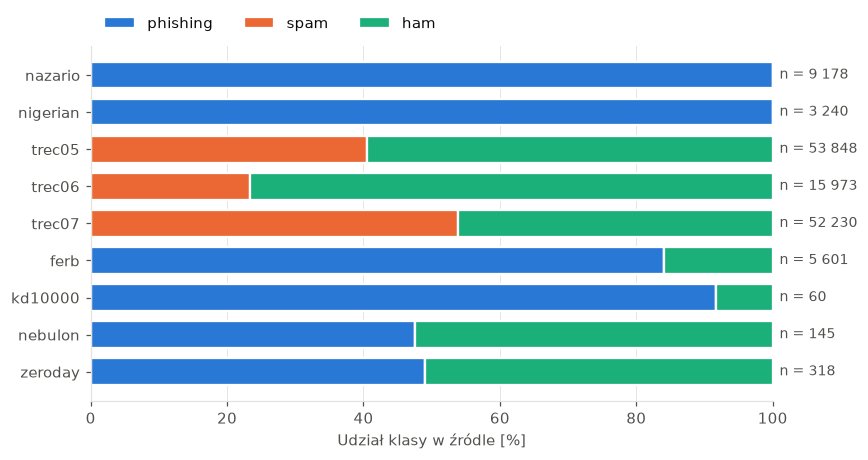

In [19]:
figure, axis = plt.subplots(figsize=(8, 4.2))
shares = composition[KIND_ORDER].div(composition["razem"], axis=0) * 100
positions = np.arange(len(SOURCE_ORDER))[::-1]
left = np.zeros(len(SOURCE_ORDER))
for kind in KIND_ORDER:
    axis.barh(positions, shares[kind], left=left, color=KIND_COLORS[kind], edgecolor="white", linewidth=1.5, height=0.72, label=kind)
    left += shares[kind].to_numpy()
for position, source in zip(positions, SOURCE_ORDER):
    axis.text(101, position, f"n = {composition.loc[source, 'razem']:,}".replace(",", " "), va="center", color=INK_SECONDARY, fontsize=9)
axis.set_yticks(positions, SOURCE_ORDER)
axis.set_xlim(0, 100)
axis.set_xlabel("Udział klasy w źródle [%]")
axis.grid(axis="y", visible=False)
axis.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0))
save_figure(figure, "f01_sklad_zrodel")

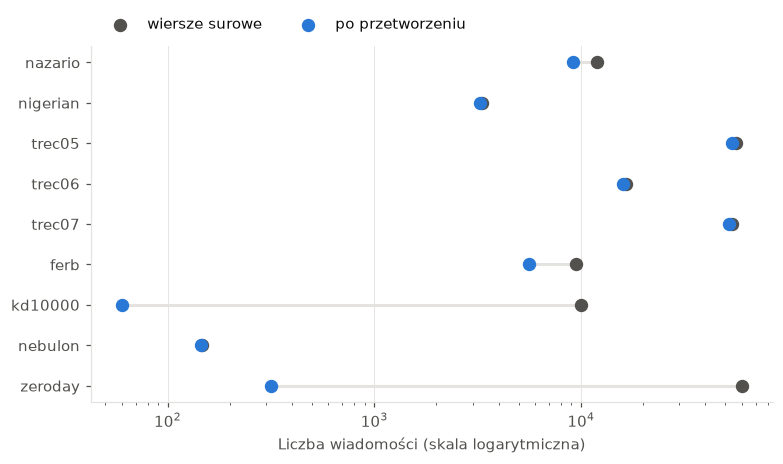

In [20]:
figure, axis = plt.subplots(figsize=(8, 4.2))
for position, source in zip(positions, SOURCE_ORDER):
    axis.plot([funnel.loc[source, "końcowe"], funnel.loc[source, "surowe"]], [position, position], color=GRID, linewidth=2, zorder=1)
axis.scatter(funnel.loc[SOURCE_ORDER, "surowe"], positions, s=60, color=INK_SECONDARY, label="wiersze surowe", zorder=2)
axis.scatter(funnel.loc[SOURCE_ORDER, "końcowe"], positions, s=60, color=KIND_COLORS["phishing"], label="po przetworzeniu", zorder=3)
axis.set_xscale("log")
axis.set_yticks(positions, SOURCE_ORDER)
axis.set_xlabel("Liczba wiadomości (skala logarytmiczna)")
axis.grid(axis="y", visible=False)
axis.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0))
save_figure(figure, "f02_lejek_przetwarzania")

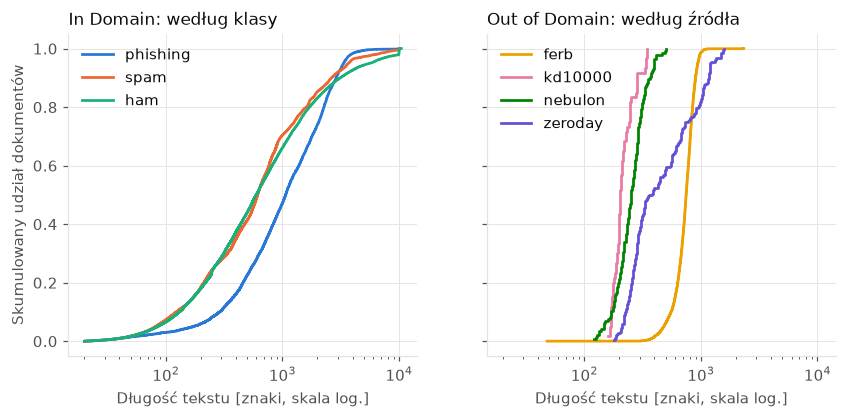

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True, sharex=True)
for kind in KIND_ORDER:
    ecdf(axes[0], meajor.loc[meajor.kind == kind, "n_chars"], color=KIND_COLORS[kind], label=kind)
for source in OOD_SOURCES:
    ecdf(axes[1], external.loc[external.source == source, "n_chars"], color=OOD_COLORS[source], label=source)
axes[0].set_title("In Domain: według klasy", loc="left")
axes[1].set_title("Out of Domain: według źródła", loc="left")
axes[0].set_ylabel("Skumulowany udział dokumentów")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xlabel("Długość tekstu [znaki, skala log.]")
    axis.legend(loc="upper left")
save_figure(figure, "f03_dlugosc_tekstow")

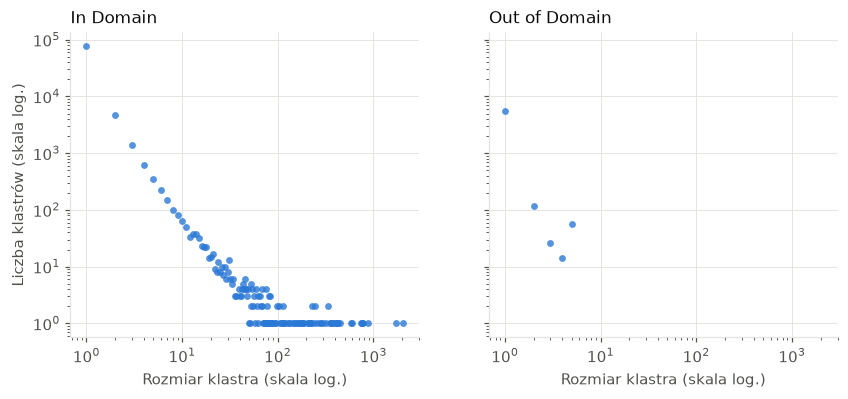

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True, sharex=True)
for axis, (corpus, frame) in zip(axes, documents.groupby("korpus")):
    frequency = frame.groupby("cluster").size().value_counts().sort_index()
    axis.scatter(frequency.index, frequency.values, s=20, color=KIND_COLORS["phishing"], alpha=0.8, linewidths=0)
    axis.set(xscale="log", yscale="log", xlabel="Rozmiar klastra (skala log.)")
    axis.set_title("In Domain" if corpus == "ID" else "Out of Domain", loc="left")
axes[0].set_ylabel("Liczba klastrów (skala log.)")
save_figure(figure, "f04_rozmiary_klastrow")

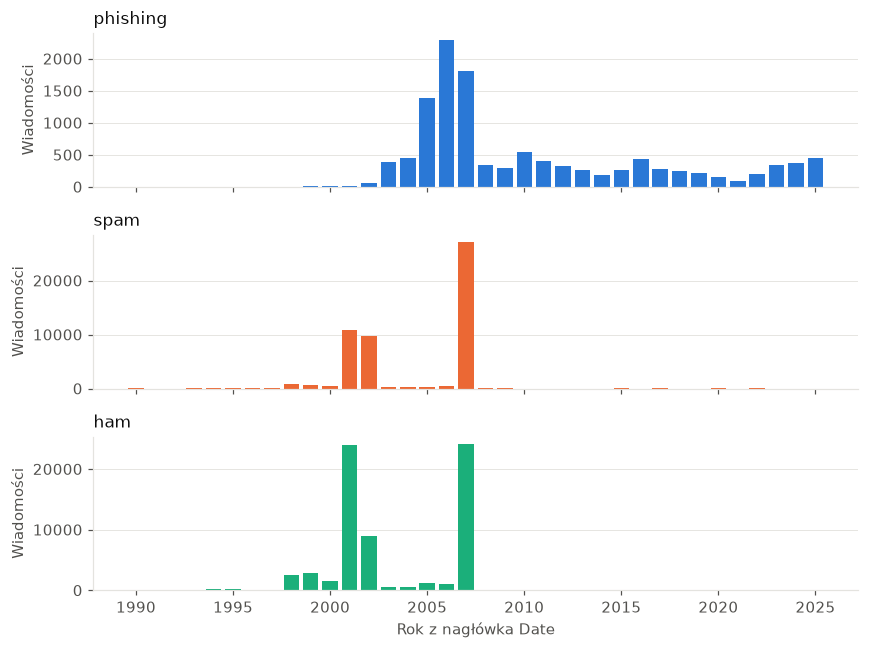

In [23]:
figure, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
for axis, kind in zip(axes, KIND_ORDER):
    counts = years[kind].dropna()
    axis.bar(counts.index.astype(int), counts.values, color=KIND_COLORS[kind], width=0.8)
    axis.set_title(kind, loc="left")
    axis.set_ylabel("Wiadomości")
    axis.grid(axis="x", visible=False)
axes[-1].set_xlabel("Rok z nagłówka Date")
figure.tight_layout()
save_figure(figure, "f05_lata_korpus_id")

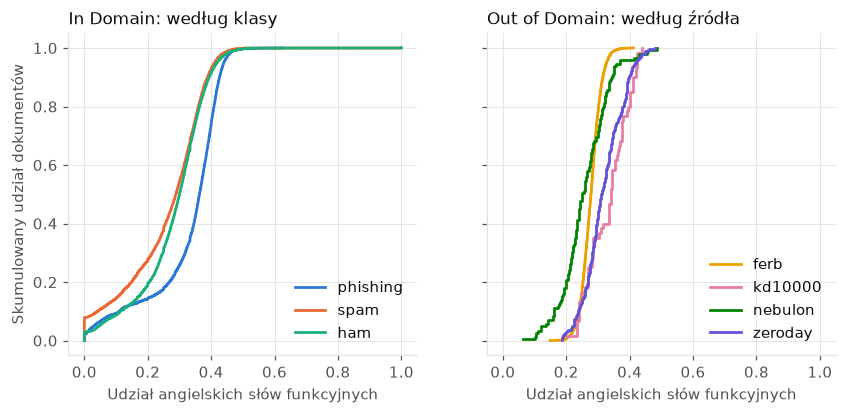

In [24]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True, sharex=True)
for kind in KIND_ORDER:
    ecdf(axes[0], meajor.loc[meajor.kind == kind, "en_ratio"], color=KIND_COLORS[kind], label=kind)
for source in OOD_SOURCES:
    ecdf(axes[1], external.loc[external.source == source, "en_ratio"], color=OOD_COLORS[source], label=source)
axes[0].set_title("In Domain: według klasy", loc="left")
axes[1].set_title("Out of Domain: według źródła", loc="left")
axes[0].set_ylabel("Skumulowany udział dokumentów")
for axis in axes:
    axis.set_xlabel("Udział angielskich słów funkcyjnych")
    axis.legend(loc="lower right")
save_figure(figure, "f06_jezyk")

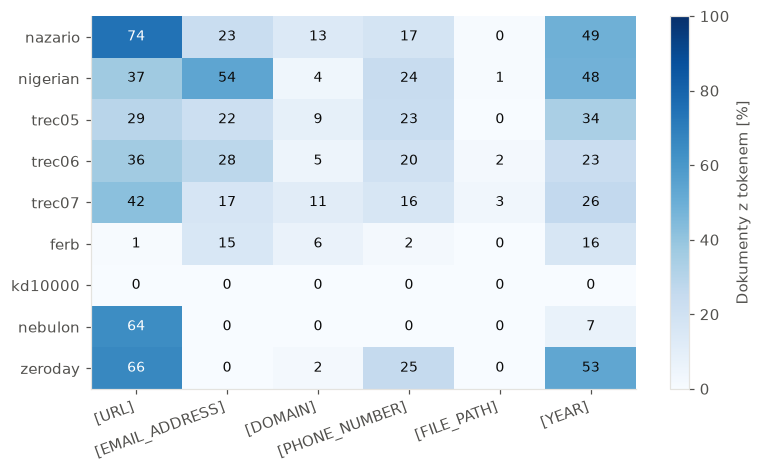

In [25]:
figure, axis = plt.subplots(figsize=(8, 4.4))
image = axis.imshow(mask_prevalence.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
axis.set_xticks(range(len(MASK_TOKENS)), MASK_TOKENS, rotation=20, ha="right")
axis.set_yticks(range(len(SOURCE_ORDER)), SOURCE_ORDER)
axis.grid(False)
for row, source in enumerate(SOURCE_ORDER):
    for column, token in enumerate(MASK_TOKENS):
        value = mask_prevalence.loc[source, token]
        axis.text(column, row, f"{value:.0f}", ha="center", va="center", fontsize=9, color="white" if value > 55 else INK)
figure.colorbar(image, ax=axis, label="Dokumenty z tokenem [%]")
save_figure(figure, "f07_tokeny_maskowania")

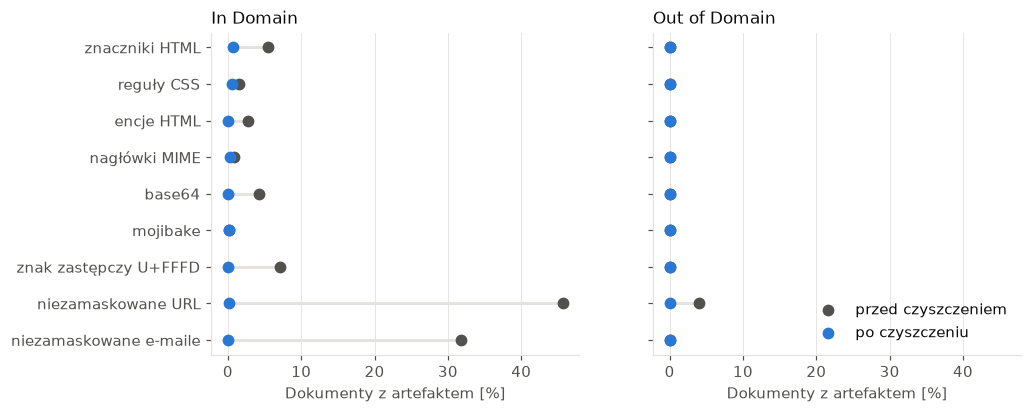

In [26]:
figure, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True, sharex=True)
names = list(ARTEFACTS)[::-1]
for axis, corpus in zip(axes, ["ID", "OOD"]):
    subset = artefacts[artefacts.korpus == corpus].set_index("artefakt").loc[names]
    axis.hlines(range(len(names)), subset.po_proc, subset.przed_proc, color=GRID, linewidth=2, zorder=1)
    axis.scatter(subset.przed_proc, range(len(names)), s=45, color=INK_SECONDARY, label="przed czyszczeniem", zorder=2)
    axis.scatter(subset.po_proc, range(len(names)), s=45, color=KIND_COLORS["phishing"], label="po czyszczeniu", zorder=3)
    axis.set_title("In Domain" if corpus == "ID" else "Out of Domain", loc="left")
    axis.set_xlabel("Dokumenty z artefaktem [%]")
    axis.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(names)), names)
axes[1].legend(loc="lower right")
save_figure(figure, "f08_artefakty")

In [27]:
print("Tabele:", sorted(path.name for path in TABLES.glob("*.csv")))
print("Wykresy:", sorted(path.name for path in FIGURES.glob("*.pdf")))

Tabele: ['t01_lejek_przetwarzania.csv', 't02_sklad_korpusow.csv', 't03_balans_klas.csv', 't04_dlugosc_tekstow.csv', 't05_klastry.csv', 't06_artefakty.csv', 't07_tokeny_maskowania.csv', 't08_nakladanie_id_ood.csv', 't09_jezyk.csv', 't10_lata_korpus_id.csv']
Wykresy: ['f01_sklad_zrodel.pdf', 'f02_lejek_przetwarzania.pdf', 'f03_dlugosc_tekstow.pdf', 'f04_rozmiary_klastrow.pdf', 'f05_lata_korpus_id.pdf', 'f06_jezyk.pdf', 'f07_tokeny_maskowania.pdf', 'f08_artefakty.pdf']
